# Predicting Annual Medical Insurance Premiums - Linear Regression

**Goal:** build a transparent, explainable model that estimates `annual_premium`
from member attributes (age, sex, BMI, children, smoker, region).

**Data:** public "Medical Cost Personal Datasets" (1,338 rows, no missing values).
`charges` is renamed to `annual_premium`. The script downloads it automatically if the
CSV is not found next to this file.

**Pipeline:** load -> stats before cleaning -> EDA -> correlations -> outliers ->
missing values -> stats after cleaning -> hypothesis tests -> encoding ->
split + scaling -> assumption checks -> model -> diagnostics -> scoring ->
regularisation -> adjusted R2 -> optional improvements -> conclusion.


## 0. Setup and configuration

In [59]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)


## 1. Data import and first look
We only observe here - no changes.

In [2]:
from google.colab import files
uploaded = files.upload()

Saving insurance_premium.csv to insurance_premium.csv


In [3]:
df = pd.read_csv("insurance_premium.csv")
df.head()

,age,sex,bmi,children,smoker,region,annual_premium
0,19,female,27.900,0,yes,southwest,16884.92
1,18,male,33.770,1,no,southeast,1725.55
2,28,male,33.000,3,no,southeast,4449.46
3,33,male,22.705,0,no,northwest,21984.47
4,32,male,28.880,0,no,northwest,3866.86


In [5]:
# Data dictionary (only for columns that exist in this file)
data_dictionary = {
    "age": "Member age in years",
    "sex": "Biological sex (male/female)",
    "bmi": "Body Mass Index (kg/m^2)",
    "children": "Number of dependents covered by the policy",
    "smoker": "Smoking status (yes/no)",
    "region": "Residential region (US)",
    TARGET: "TARGET - annual insurance premium billed (USD)",
}
pd.DataFrame([(c, data_dictionary.get(c, "-")) for c in df.columns],
             columns=["feature", "description"])

,feature,description
0,age,Member age in years
1,sex,Biological sex (male/female)
2,bmi,Body Mass Index (kg/m^2)
3,children,Number of dependents covered by the policy
4,smoker,Smoking status (yes/no)
5,region,Residential region (US)
6,annual_premium,TARGET - annual insurance premium billed (USD)


## 2. Data statistics BEFORE cleaning
Snapshot of dtypes, numeric/categorical summaries and missing values.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             1338 non-null   int64  
 1   sex             1338 non-null   object 
 2   bmi             1338 non-null   float64
 3   children        1338 non-null   int64  
 4   smoker          1338 non-null   object 
 5   region          1338 non-null   object 
 6   annual_premium  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [8]:
# Numeric summary (count, mean, std, min, quartiles, max)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.00,27.00000,39.00,51.00000,64.00
bmi,1338.0,30.663397,6.098187,15.96,26.29625,30.40,34.69375,53.13
children,1338.0,1.094918,1.205493,0.00,0.00000,1.00,2.00000,5.00
annual_premium,1338.0,13270.422280,12110.011259,1121.87,4740.28750,9382.03,16639.91500,63770.43


In [9]:
# Categorical summary
df.describe(exclude=np.number).T

,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


In [10]:
# Missing-value audit
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
print("Total missing cells:", int(df.isna().sum().sum()))
missing[missing["missing_count"] > 0]

Total missing cells: 0


,missing_count,missing_pct


In [11]:
# Column lists reused throughout
numeric_cols = df.select_dtypes(include=np.number).columns.drop(TARGET).tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()
binary_cols = [c for c in categorical_cols if df[c].nunique() == 2]
multi_cols = [c for c in categorical_cols if df[c].nunique() > 2]
print("Numeric     :", numeric_cols)
print("Categorical :", categorical_cols)
print("  binary    :", binary_cols)
print("  multi-level:", multi_cols)
print("Target      :", TARGET)

Numeric     : ['age', 'bmi', 'children']
Categorical : ['sex', 'smoker', 'region']
  binary    : ['sex', 'smoker']
  multi-level: ['region']
Target      : annual_premium


## 3. Exploratory Data Analysis (EDA)
Target distribution, feature distributions, category balance, feature-vs-target.

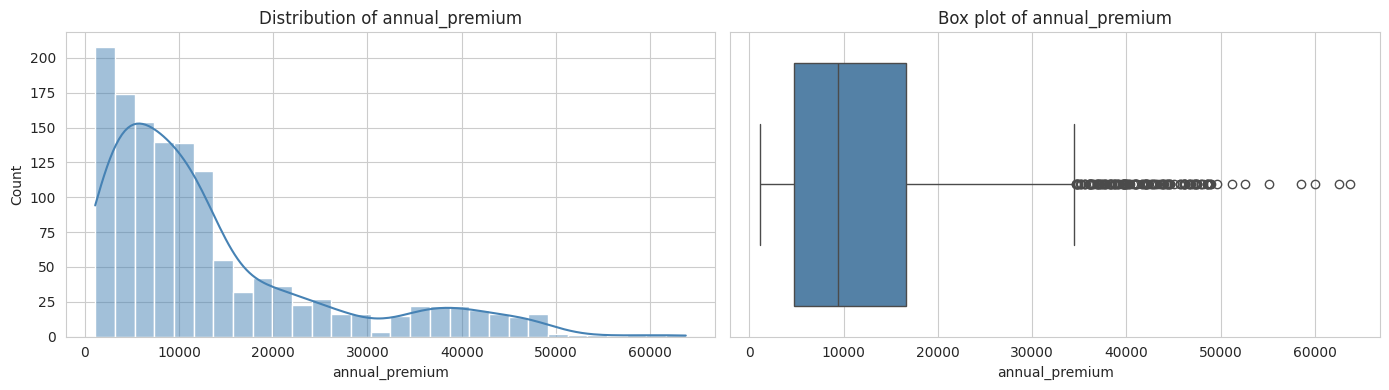

Skewness of target: 1.516


In [12]:
# 3a. Target distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[TARGET], kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of annual_premium")
sns.boxplot(x=df[TARGET], ax=ax[1], color="steelblue")
ax[1].set_title("Box plot of annual_premium")
plt.tight_layout()
plt.show()
print(f"Skewness of target: {df[TARGET].skew():.3f}")

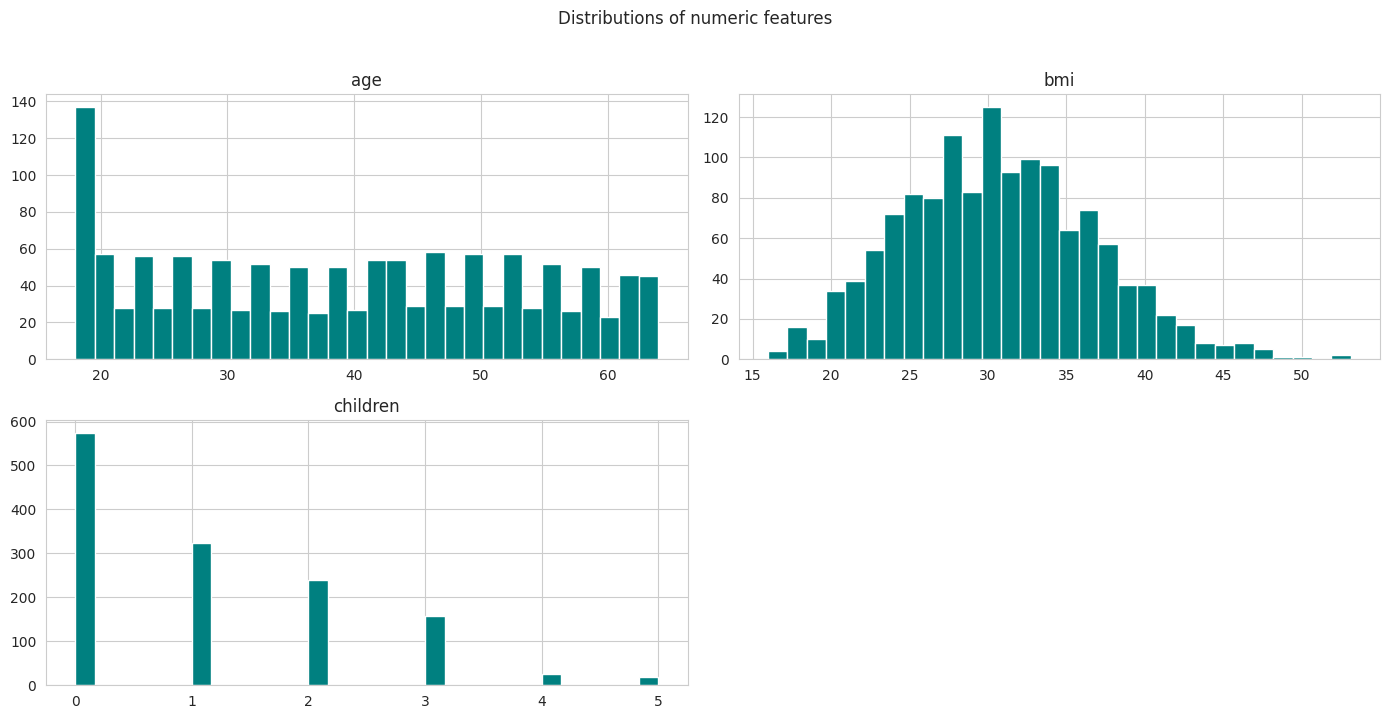

In [13]:
# 3b. Histograms of numeric features
df[numeric_cols].hist(bins=30, figsize=(14, 7), color="teal", edgecolor="white")
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout()
plt.show()

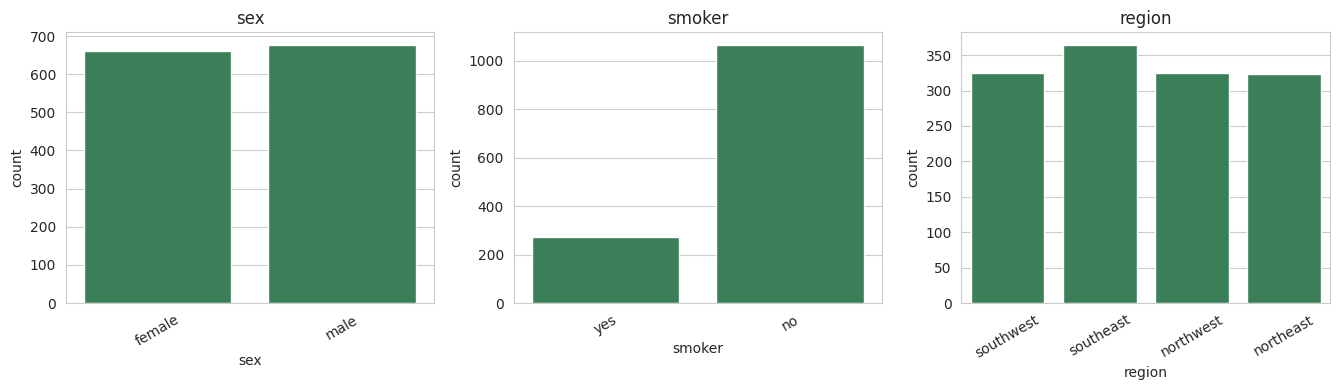

In [14]:
# 3c. Count plots of categorical features
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(4.5 * len(categorical_cols), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, categorical_cols):
    sns.countplot(x=col, data=df, ax=ax, color="seagreen")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

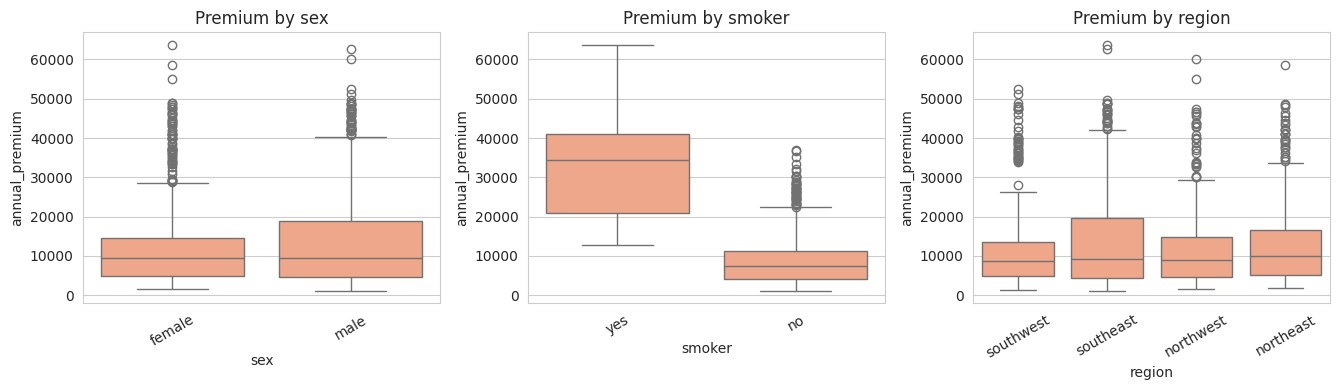

In [15]:
# 3d. Premium across each categorical feature
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(4.5 * len(categorical_cols), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, categorical_cols):
    sns.boxplot(x=col, y=TARGET, data=df, ax=ax, color="lightsalmon")
    ax.set_title(f"Premium by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

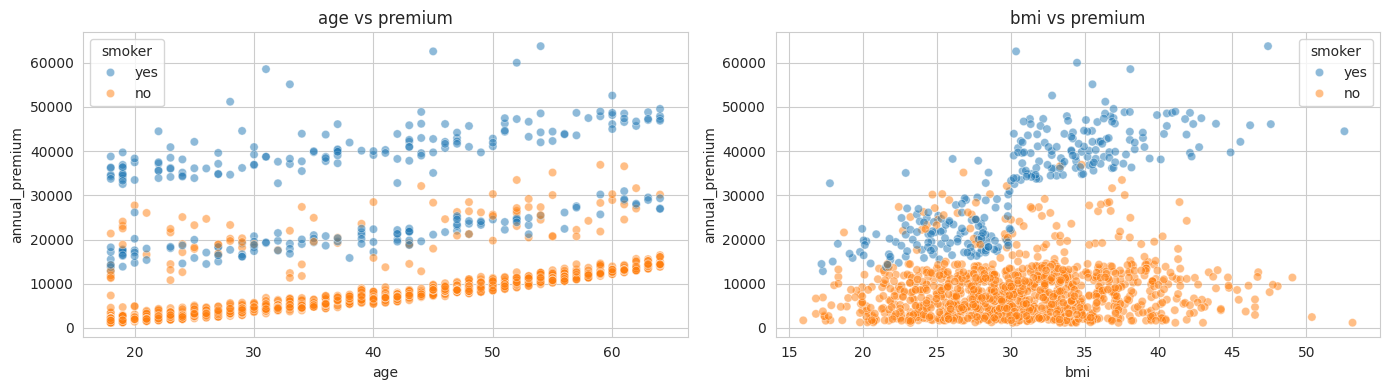

In [16]:
# 3e. Age and BMI vs premium, coloured by smoker (if available)
hue_col = "smoker" if "smoker" in df.columns else None
plot_feats = [c for c in ["age", "bmi"] if c in df.columns] or numeric_cols[:2]
fig, axes = plt.subplots(1, len(plot_feats), figsize=(7 * len(plot_feats), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, plot_feats):
    sns.scatterplot(x=col, y=TARGET, hue=hue_col, data=df, alpha=0.5, ax=ax)
    ax.set_title(f"{col} vs premium")
plt.tight_layout()
plt.show()

## 4. Correlations BEFORE cleaning
Pearson correlation on numeric columns (NaNs are ignored pairwise).

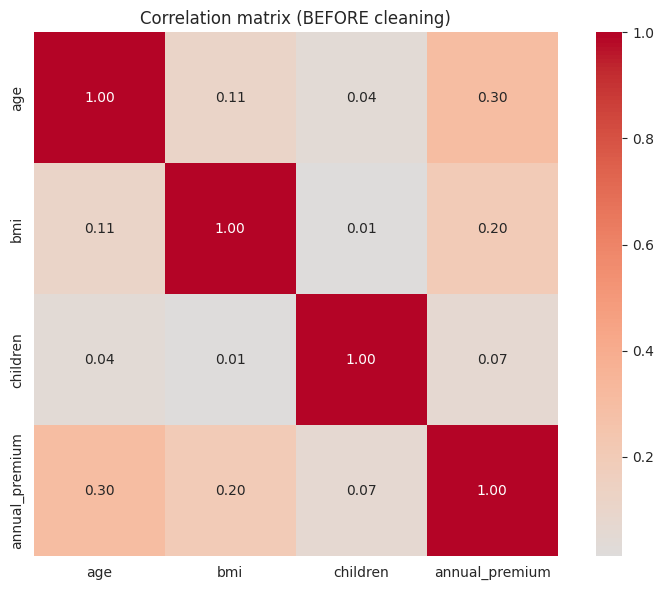

In [17]:
corr_before = df[numeric_cols + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_before, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (BEFORE cleaning)")
plt.tight_layout()
plt.show()

In [18]:
# Ranked correlation of each numeric feature with the target
corr_before[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

,annual_premium
age,0.299008
bmi,0.198341
children,0.067998


## 5. Outlier detection (IQR rule)
A value is an outlier if it is below Q1 - 1.5*IQR or above Q3 + 1.5*IQR.

**Change vs. the original notebook:** only the *features* are capped. The target is
reported but NOT capped - capping the premium would flatten the genuinely expensive
(mostly smoker) policies the model is supposed to learn.

In [19]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


rows = []
for col in numeric_cols + [TARGET]:
    lo, hi = iqr_bounds(df[col])
    rows.append([col, round(lo, 1), round(hi, 1), int(((df[col] < lo) | (df[col] > hi)).sum())])
pd.DataFrame(rows, columns=["feature", "lower_bound", "upper_bound", "n_outliers"])

,feature,lower_bound,upper_bound,n_outliers
0,age,-9.0,87.0,0
1,bmi,13.7,47.3,9
2,children,-3.0,5.0,0
3,annual_premium,-13109.2,34489.4,139


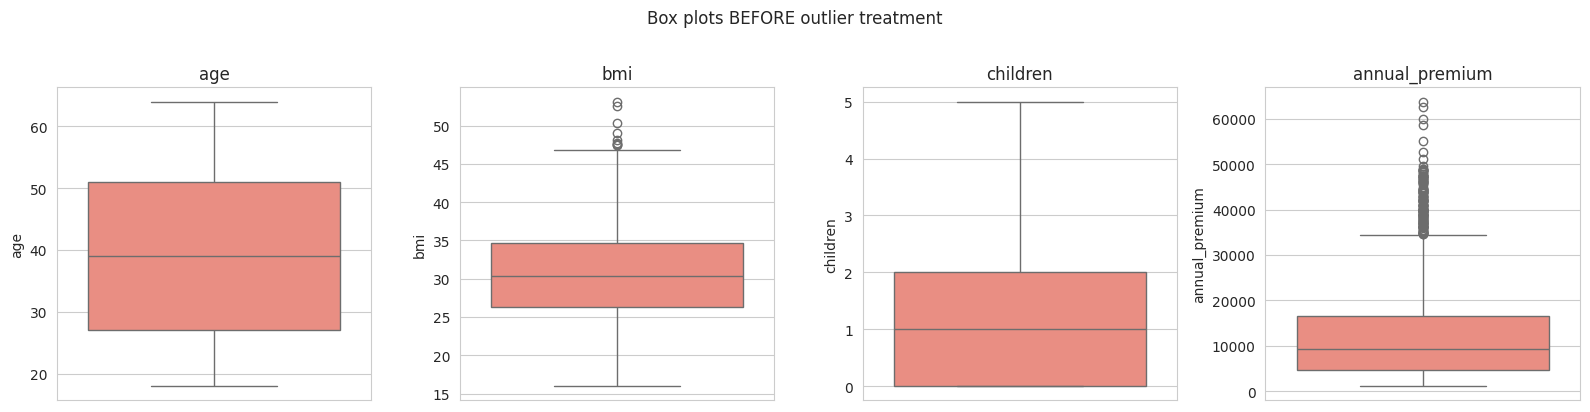

In [20]:
# Box plots BEFORE treatment
cols_to_plot = numeric_cols + [TARGET]
n_cols = 4
n_rows = int(np.ceil(len(cols_to_plot) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, col in zip(axes, cols_to_plot):
    sns.boxplot(y=df[col], ax=ax, color="salmon")
    ax.set_title(col)
for ax in axes[len(cols_to_plot):]:
    ax.axis("off")
plt.suptitle("Box plots BEFORE outlier treatment", y=1.02)
plt.tight_layout()
plt.show()

In [21]:
# Cap (winsorise) numeric FEATURES at their IQR bounds, on a copy
df_capped = df.copy()
for col in numeric_cols:
    lo, hi = iqr_bounds(df_capped[col])
    df_capped[col] = df_capped[col].clip(lower=lo, upper=hi)

after = [[c, int(((df_capped[c] < iqr_bounds(df_capped[c])[0]) |
                  (df_capped[c] > iqr_bounds(df_capped[c])[1])).sum())] for c in numeric_cols]
print("Remaining IQR-flagged points after capping (small residual counts are normal):")
pd.DataFrame(after, columns=["feature", "n_outliers_after"])

Remaining IQR-flagged points after capping (small residual counts are normal):


,feature,n_outliers_after
0,age,0
1,bmi,0
2,children,0


## 6. Missing-value imputation
* Categorical -> **mode**.
* Numeric -> **KNN** (k=5). Features are standardised first so that large-scale
  columns (e.g. income) do not dominate the distance calculation.
* Mean / median shown for comparison: mean suits symmetric data, median suits skewed data.

In [22]:
# 6a. Mean vs median vs mode fill on one column
demo_col = "bmi" if "bmi" in numeric_cols else numeric_cols[0]
print(f"{demo_col} mean fill   : {df_capped[demo_col].mean():.2f}")
print(f"{demo_col} median fill : {df_capped[demo_col].median():.2f}")
print(f"{demo_col} mode fill   : {df_capped[demo_col].mode()[0]:.2f}")

bmi mean fill   : 30.65
bmi median fill : 30.40
bmi mode fill   : 32.30


In [23]:
# 6b. Categorical columns: mode imputation
df_clean = df_capped.copy()
if categorical_cols:
    df_clean[categorical_cols] = SimpleImputer(strategy="most_frequent").fit_transform(df_clean[categorical_cols])
print("Categorical missing after mode imputation:")
print(df_clean[categorical_cols].isna().sum())

Categorical missing after mode imputation:
sex       0
smoker    0
region    0
dtype: int64


In [24]:
# 6c. Numeric columns: scaled KNN imputation
int_like = [c for c in numeric_cols if (df[c].dropna() % 1 == 0).all()]   # e.g. age, children
imp_scaler = StandardScaler()
scaled = imp_scaler.fit_transform(df_clean[numeric_cols])                 # NaNs are ignored in fit
imputed = KNNImputer(n_neighbors=5, weights="distance").fit_transform(scaled)
df_clean[numeric_cols] = imp_scaler.inverse_transform(imputed)
df_clean[int_like] = df_clean[int_like].round()                           # keep counts whole
print("Numeric missing after KNN imputation:")
print(df_clean[numeric_cols].isna().sum())

Numeric missing after KNN imputation:
age         0
bmi         0
children    0
dtype: int64


In [25]:
# 6d. Confirm the dataset is clean
assert df_clean.isna().sum().sum() == 0, "There are still missing values!"
print("No missing values remain. Cleaning complete.")

No missing values remain. Cleaning complete.


## 7. Data statistics AFTER cleaning

In [26]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.00,27.00000,39.00,51.00000,64.00
bmi,1338.0,30.650034,6.056926,15.96,26.29625,30.40,34.69375,47.29
children,1338.0,1.094918,1.205493,0.00,0.00000,1.00,2.00000,5.00
annual_premium,1338.0,13270.422280,12110.011259,1121.87,4740.28750,9382.03,16639.91500,63770.43


In [27]:
# Mean / std before vs after cleaning
pd.DataFrame({
    "mean_before": df[numeric_cols + [TARGET]].mean(),
    "mean_after": df_clean[numeric_cols + [TARGET]].mean(),
    "std_before": df[numeric_cols + [TARGET]].std(),
    "std_after": df_clean[numeric_cols + [TARGET]].std(),
}).round(2)

,mean_before,mean_after,std_before,std_after
age,39.21,39.21,14.05,14.05
bmi,30.66,30.65,6.10,6.06
children,1.09,1.09,1.21,1.21
annual_premium,13270.42,13270.42,12110.01,12110.01


## 8. Correlations and scatter plots AFTER cleaning

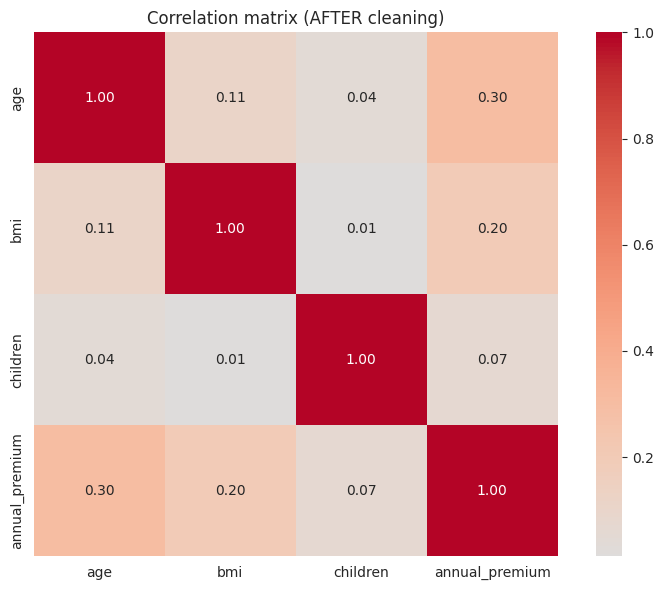

In [28]:
corr_after = df_clean[numeric_cols + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_after, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (AFTER cleaning)")
plt.tight_layout()
plt.show()

In [29]:
corr_target = corr_after[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlation of each numeric feature with annual_premium:")
corr_target

Correlation of each numeric feature with annual_premium:


,annual_premium
age,0.299008
bmi,0.198997
children,0.067998


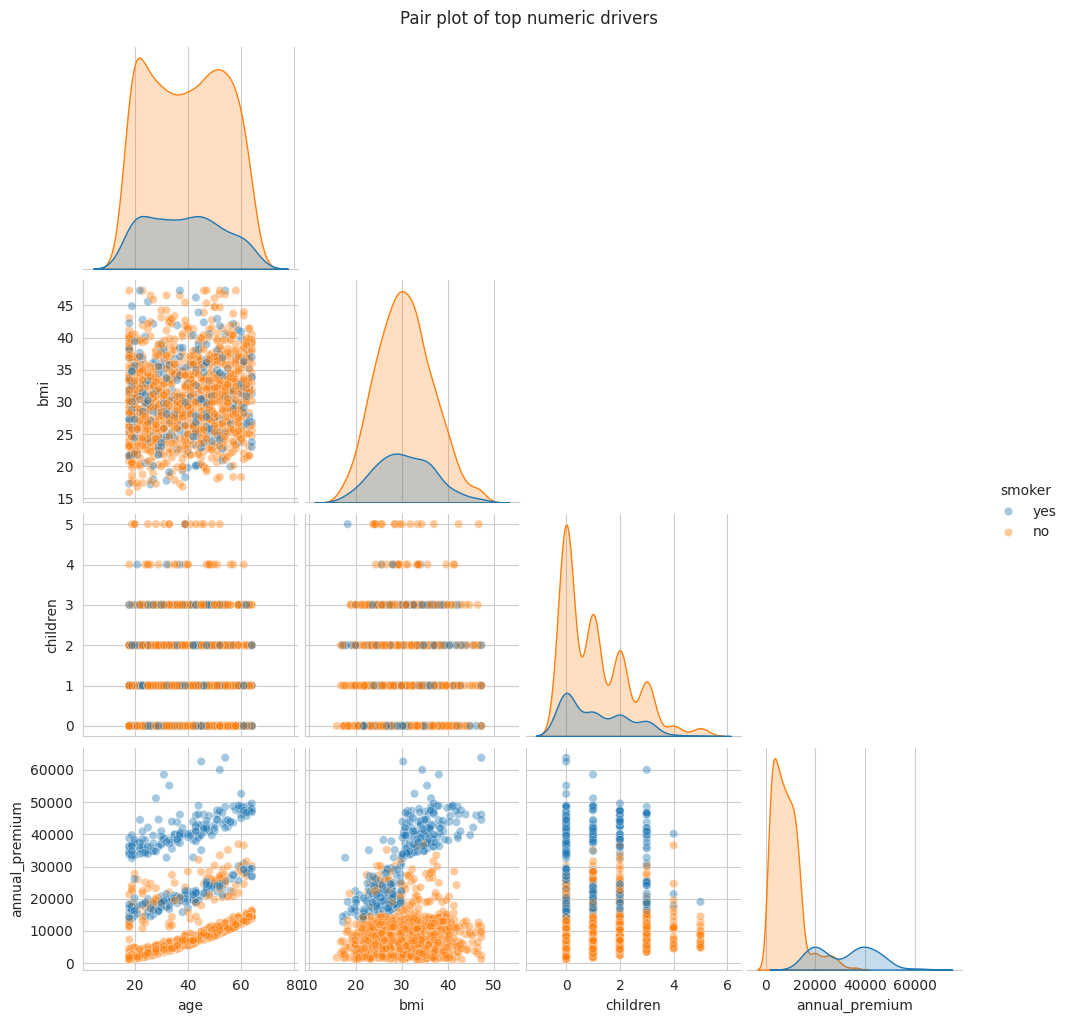

In [30]:
# Pair plot of the strongest numeric drivers, coloured by smoker (if available)
top_feats = corr_target.head(3).index.tolist()
pair_cols = top_feats + [TARGET] + ([hue_col] if hue_col else [])
sns.pairplot(df_clean[pair_cols], hue=hue_col, corner=True, plot_kws={"alpha": 0.4})
plt.suptitle("Pair plot of top numeric drivers", y=1.02)
plt.show()

## 9. Hypothesis testing on categorical variables
* **Welch t-test** - binary category: do the two group means differ?
* **One-way ANOVA** - multi-level category: do the group means differ?
* **Chi-square** - are two categorical variables associated?

Decision rule: p < 0.05 -> reject "no difference" -> the variable is significant.

In [31]:
# 9a. t-tests for binary columns
for col in binary_cols:
    lvl_a, lvl_b = sorted(df_clean[col].unique())
    a = df_clean.loc[df_clean[col] == lvl_a, TARGET]
    b = df_clean.loc[df_clean[col] == lvl_b, TARGET]
    t_stat, p_val = stats.ttest_ind(a, b, equal_var=False)
    print(f"T-TEST {col}: mean({lvl_a})={a.mean():,.0f}  mean({lvl_b})={b.mean():,.0f}  "
          f"t={t_stat:.3f}  p={p_val:.3e}  ->", "SIGNIFICANT" if p_val < 0.05 else "not significant")

T-TEST sex: mean(female)=12,570  mean(male)=13,957  t=-2.101  p=3.584e-02  -> SIGNIFICANT
T-TEST smoker: mean(no)=8,434  mean(yes)=32,050  t=-32.752  p=5.889e-103  -> SIGNIFICANT


In [32]:
# 9b. ANOVA for multi-level columns
for col in multi_cols:
    groups = [g[TARGET].values for _, g in df_clean.groupby(col)]
    f_stat, p_val = stats.f_oneway(*groups)
    print(f"ANOVA {col}: F={f_stat:.3f}  p={p_val:.3e}  ->",
          "SIGNIFICANT" if p_val < 0.05 else "not significant")

ANOVA region: F=2.970  p=3.089e-02  -> SIGNIFICANT


In [33]:
# 9c. Chi-square between two categorical variables (smoker vs region if available)
if len(categorical_cols) >= 2:
    pair = ("smoker", "region") if {"smoker", "region"} <= set(categorical_cols) else tuple(categorical_cols[:2])
    ct = pd.crosstab(df_clean[pair[0]], df_clean[pair[1]])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    print(f"CHI-SQUARE {pair[0]} vs {pair[1]}")
    print(ct)
    print(f"chi2={chi2:.3f}  dof={dof}  p={p_val:.3e}  ->",
          "associated" if p_val < 0.05 else "independent")

CHI-SQUARE smoker vs region
region  northeast  northwest  southeast  southwest
smoker                                            
no            257        267        273        267
yes            67         58         91         58
chi2=7.343  dof=3  p=6.172e-02  -> independent


## 10. Encoding categorical variables
* Binary columns -> 0/1 (alphabetically second level = 1, e.g. male=1, yes=1).
* Multi-level columns -> one-hot with `drop_first=True` (avoids the dummy-variable trap).
* Target encoding is shown for teaching only (it leaks the target if used naively).

In [34]:
df_enc = df_clean.copy()
for col in binary_cols:
    lvl_a, lvl_b = sorted(df_enc[col].unique())
    df_enc[col] = df_enc[col].map({lvl_a: 0, lvl_b: 1})
    print(f"{col}: {lvl_a}=0, {lvl_b}=1")

sex: female=0, male=1
smoker: no=0, yes=1


In [35]:
# Illustration only: target (mean) encoding of the first multi-level column
if multi_cols:
    print(f"Target (mean-premium) encoding for {multi_cols[0]}:")
    print(df_enc.groupby(multi_cols[0])[TARGET].mean().round(0))

Target (mean-premium) encoding for region:
region
northeast    13406.0
northwest    12418.0
southeast    14735.0
southwest    12347.0
Name: annual_premium, dtype: float64


In [36]:
# Final approach: one-hot encoding
df_enc = pd.get_dummies(df_enc, columns=multi_cols, drop_first=True, dtype=int)
print("Feature columns after encoding:", [c for c in df_enc.columns if c != TARGET])
df_enc.head()

Feature columns after encoding: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest']


,age,sex,bmi,children,smoker,annual_premium,region_northwest,region_southeast,region_southwest
0,19.0,0,27.900,0.0,1,16884.92,0,0,1
1,18.0,1,33.770,1.0,0,1725.55,0,1,0
2,28.0,1,33.000,3.0,0,4449.46,0,1,0
3,33.0,1,22.705,0.0,0,21984.47,1,0,0
4,32.0,1,28.880,0.0,0,3866.86,1,0,0


## 11. Train / validation / test split and scaling
Split first, scale second - the scaler learns mean/std from the TRAIN set only.
Split: 60% train / 20% validation / 20% test.

In [37]:
X = df_enc.drop(columns=[TARGET])
y = df_enc[TARGET]
feature_names = X.columns.tolist()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)}  Validation: {len(X_val)}  Test: {len(X_test)}")

Train: 802  Validation: 268  Test: 268


In [38]:
scaler = StandardScaler().fit(X_train)


def to_scaled(frame):
    return pd.DataFrame(scaler.transform(frame), columns=feature_names, index=frame.index)


X_train_s, X_val_s, X_test_s = to_scaled(X_train), to_scaled(X_val), to_scaled(X_test)
print("Mean of scaled training features (should be ~0):")
X_train_s.mean().round(3)

Mean of scaled training features (should be ~0):


,0
age,0.0
sex,-0.0
bmi,0.0
children,0.0
smoker,-0.0
region_northwest,0.0
region_southeast,-0.0
region_southwest,0.0


## 12. Checking the assumptions of linear regression
Each check prints an explicit PASS / WARNING verdict.
1. Linearity - Ramsey RESET test (the original residual-vs-fitted correlation was always ~0 for OLS by construction, so it could never fail)
2. No multicollinearity - VIF
3. Independent errors - Durbin-Watson (rows have no time order here, so this is informational)
4. Constant variance - Breusch-Pagan
5. Normal residuals - Jarque-Bera + Q-Q plot

In [39]:
# 12a. Multicollinearity: VIF (<5 fine, 5-10 moderate, >10 problematic)
vif_df = pd.DataFrame({
    "feature": feature_names,
    "VIF": [variance_inflation_factor(X_train_s.values, i) for i in range(X_train_s.shape[1])],
}).sort_values("VIF", ascending=False)
print(vif_df.to_string(index=False))
if (vif_df["VIF"] < 10).all():
    print("\nPASS: no feature has VIF >= 10 -> multicollinearity acceptable.")
else:
    print("\nWARNING: some features have VIF >= 10 -> consider dropping/combining them.")

         feature      VIF
region_southeast 1.623527
region_southwest 1.537305
region_northwest 1.486995
             bmi 1.114192
             age 1.021613
          smoker 1.020114
             sex 1.007500
        children 1.004094

PASS: no feature has VIF >= 10 -> multicollinearity acceptable.


In [40]:
# 12b. Baseline OLS (statsmodels) - gives residuals and the inference table (p-values, CIs)
X_train_sm = sm.add_constant(X_train_s)
ols = sm.OLS(y_train.values, X_train_sm).fit()
residuals = ols.resid
fitted = ols.fittedvalues
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.746
Model:                            OLS   Adj. R-squared:                  0.744
Method:                 Least Squares   F-statistic:                     291.4
Date:                Wed, 14 Oct 2026   Prob (F-statistic):          3.50e-230
Time:                        15:17:14   Log-Likelihood:                -8097.8
No. Observations:                 802   AIC:                         1.621e+04
Df Residuals:                     793   BIC:                         1.626e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             1.304e+04    208.547  

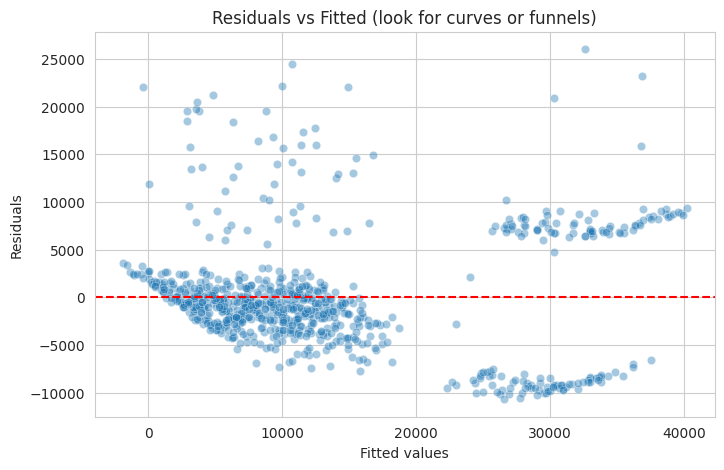

Ramsey RESET p-value = 0.0000


In [41]:
# 12c. Linearity: residuals-vs-fitted plot + Ramsey RESET test
plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted, y=residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (look for curves or funnels)")
plt.show()

reset_p = float(linear_reset(ols, power=2, test_type="fitted", use_f=True).pvalue)
print(f"Ramsey RESET p-value = {reset_p:.4f}")
if reset_p > 0.05:
    print("PASS: no evidence of missing non-linear terms.")
else:
    print("WARNING: p < 0.05 -> relationship is not fully linear (try interactions / transforms, see section 18).")

In [42]:
# 12d. Independence of errors: Durbin-Watson (ideal ~2)
dw = durbin_watson(residuals)
print(f"Durbin-Watson = {dw:.3f}")
print("PASS: no strong autocorrelation." if 1.5 < dw < 2.5 else "WARNING: possible autocorrelation.")

Durbin-Watson = 2.107
PASS: no strong autocorrelation.


In [43]:
# 12e. Homoscedasticity: Breusch-Pagan (null = constant variance)
bp_p = het_breuschpagan(residuals, X_train_sm)[1]
print(f"Breusch-Pagan p-value = {bp_p:.4g}")
print("PASS: homoscedastic." if bp_p > 0.05 else
      "WARNING: heteroscedasticity (common with cost data; consider log target or robust SEs).")

Breusch-Pagan p-value = 4.046e-14


Jarque-Bera p-value = 2.963e-91


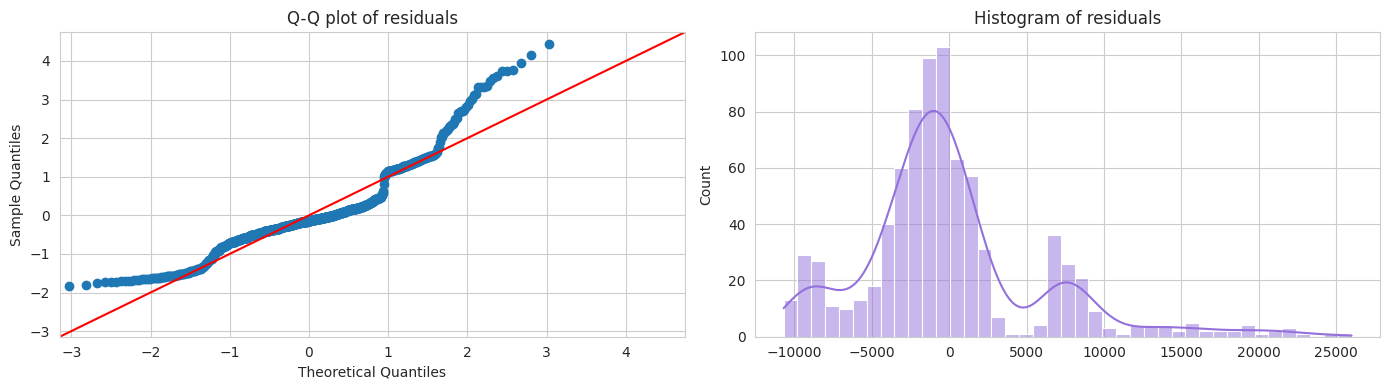

In [44]:
# 12f. Normality of residuals: Jarque-Bera + Q-Q plot
jb_p = stats.jarque_bera(residuals)[1]
print(f"Jarque-Bera p-value = {jb_p:.4g}")
print("PASS: residuals consistent with normality." if jb_p > 0.05 else
      "WARNING: residuals are not normal (right-skewed target is the usual cause).")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sm.qqplot(residuals, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot of residuals")
sns.histplot(residuals, kde=True, ax=ax[1], color="mediumpurple")
ax[1].set_title("Histogram of residuals")
plt.tight_layout()
plt.show()

## 13. Building the linear model
scikit-learn `LinearRegression` (OLS). Scaled coefficients show relative importance;
dividing by the scaler's std converts them to **USD per one unit** of each raw feature.

In [45]:
lin_reg = LinearRegression().fit(X_train_s, y_train)

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef_scaled": lin_reg.coef_,
    "usd_per_unit": lin_reg.coef_ / scaler.scale_,
}).sort_values("coef_scaled", key=abs, ascending=False)
print(f"Intercept: {lin_reg.intercept_:,.1f}")
coef_df.round(2)

Intercept: 13,039.8


,feature,coef_scaled,usd_per_unit
4,smoker,9396.12,23244.02
0,age,3561.11,253.31
2,bmi,2110.46,346.14
3,children,497.87,402.39
7,region_southwest,-335.35,-758.18
6,region_southeast,-260.84,-600.90
5,region_northwest,-194.83,-462.49
1,sex,-75.27,-150.59


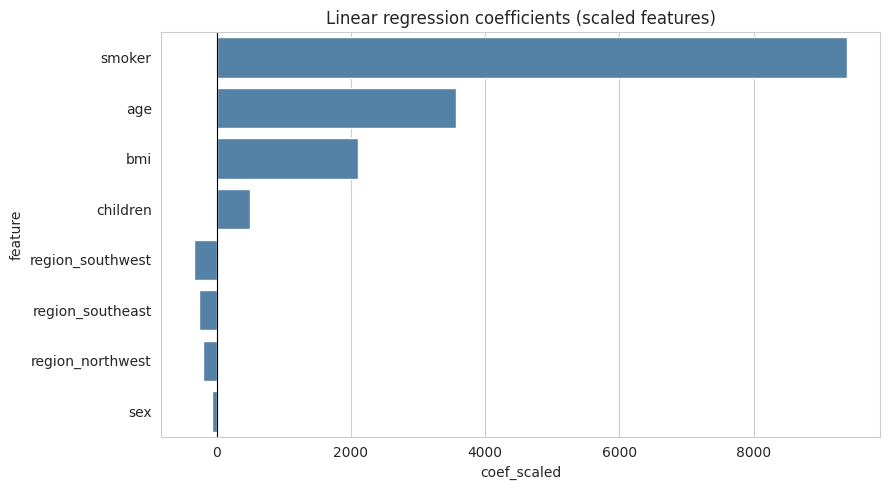

In [46]:
plt.figure(figsize=(9, 5))
sns.barplot(x="coef_scaled", y="feature", data=coef_df, color="steelblue")
plt.title("Linear regression coefficients (scaled features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 14. Residual diagnostics on the validation set

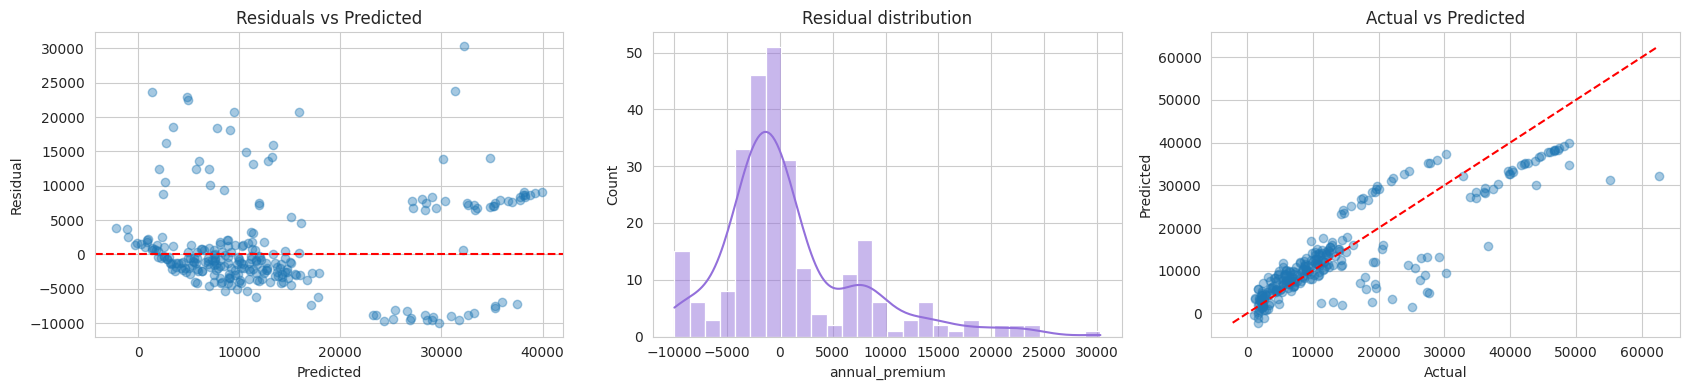

In [47]:
val_pred = lin_reg.predict(X_val_s)
val_resid = y_val - val_pred

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].scatter(val_pred, val_resid, alpha=0.4)
axes[0].axhline(0, color="red", ls="--")
axes[0].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs Predicted")
sns.histplot(val_resid, kde=True, ax=axes[1], color="mediumpurple")
axes[1].set_title("Residual distribution")
axes[2].scatter(y_val, val_pred, alpha=0.4)
lims = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
axes[2].plot(lims, lims, "r--")
axes[2].set(xlabel="Actual", ylabel="Predicted", title="Actual vs Predicted")
plt.tight_layout()
plt.show()

## 15. Train / validation / test scoring and over/under-fitting check
* train R2 >> validation R2 -> overfitting
* all scores low -> underfitting
* close scores -> generalises well

Cross-validation uses a **Pipeline** so the scaler is re-fitted inside each fold (no leakage).

In [48]:
def report_scores(model, name):
    r2_tr = r2_score(y_train, model.predict(X_train_s))
    r2_va = r2_score(y_val, model.predict(X_val_s))
    r2_te = r2_score(y_test, model.predict(X_test_s))
    print(f"{name:16s} train R2={r2_tr:.4f}  val R2={r2_va:.4f}  test R2={r2_te:.4f}")
    return r2_tr, r2_va, r2_te


r2_tr, r2_va, r2_te = report_scores(lin_reg, "LinearRegression")
if r2_tr - r2_va > 0.05:
    print("-> Signs of OVERFITTING (train much higher than validation).")
elif r2_tr < 0.5:
    print("-> Signs of UNDERFITTING / limited fit (R2 below 0.5).")
elif r2_tr < 0.8:
    print("-> No overfitting, but only moderate fit: the linear form leaves variance unexplained.")
else:
    print("-> Good generalisation: scores are high and close across splits.")

LinearRegression train R2=0.7462  val R2=0.7283  test R2=0.7816
-> No overfitting, but only moderate fit: the linear form leaves variance unexplained.


In [49]:
# 5-fold cross-validation (scaler inside the pipeline)
cv_scores = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                            X_train_full, y_train_full, cv=5, scoring="r2")
print("5-fold CV R2:", np.round(cv_scores, 4))
print(f"Mean CV R2 = {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")

5-fold CV R2: [0.7162 0.8024 0.7241 0.6583 0.7669]
Mean CV R2 = 0.7336  (+/- 0.0488)


In [50]:
# Test-set errors in USD
test_pred = lin_reg.predict(X_test_s)
print(f"Test RMSE = {np.sqrt(mean_squared_error(y_test, test_pred)):,.1f} USD")
print(f"Test MAE  = {mean_absolute_error(y_test, test_pred):,.1f} USD")

Test RMSE = 5,823.2 USD
Test MAE  = 4,185.7 USD


## 16. Regularisation - Ridge, Lasso, Elastic Net
* Ridge (L2) shrinks coefficients smoothly.
* Lasso (L1) can set coefficients exactly to zero (feature selection).
* Elastic Net blends both.
Alpha is tuned by cross-validation on the training set (the original used a fixed alpha=1).

In [51]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV

alphas = np.logspace(-3, 3, 50)
ridge = RidgeCV(alphas=alphas).fit(X_train_s, y_train)
lasso = LassoCV(alphas=alphas, cv=5, max_iter=20000, random_state=RANDOM_STATE).fit(X_train_s, y_train)
enet = ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=20000,
                    random_state=RANDOM_STATE).fit(X_train_s, y_train)
print(f"Best alpha  Ridge={ridge.alpha_:.3g}  Lasso={lasso.alpha_:.3g}  "
      f"ElasticNet={enet.alpha_:.3g} (l1_ratio={enet.l1_ratio_})")

models = [(lin_reg, "Linear"), (ridge, "Ridge"), (lasso, "Lasso"), (enet, "ElasticNet")]
for mdl, nm in models:
    report_scores(mdl, nm)

Best alpha  Ridge=3.56  Lasso=139  ElasticNet=0.0126 (l1_ratio=0.5)
Linear           train R2=0.7462  val R2=0.7283  test R2=0.7816
Ridge            train R2=0.7462  val R2=0.7280  test R2=0.7812
Lasso            train R2=0.7451  val R2=0.7261  test R2=0.7778
ElasticNet       train R2=0.7461  val R2=0.7278  test R2=0.7811


In [52]:
# Coefficient comparison (note any zeros under Lasso / ElasticNet)
pd.DataFrame({
    "Linear": lin_reg.coef_, "Ridge": ridge.coef_,
    "Lasso": lasso.coef_, "ElasticNet": enet.coef_,
}, index=feature_names).round(1)

,Linear,Ridge,Lasso,ElasticNet
age,3561.1,3543.0,3430.6,3535.3
sex,-75.3,-71.9,-0.0,-70.4
bmi,2110.5,2100.3,1928.4,2096.0
children,497.9,497.5,364.1,497.4
smoker,9396.1,9352.6,9251.4,9334.2
region_northwest,-194.8,-194.8,-0.0,-194.8
region_southeast,-260.8,-254.4,-0.0,-251.7
region_southwest,-335.3,-332.1,-36.5,-330.7


In [53]:
# Test-set summary for every model
def metrics_row(model, name):
    pred = model.predict(X_test_s)
    return {"model": name, "test_R2": r2_score(y_test, pred),
            "test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "test_MAE": mean_absolute_error(y_test, pred)}


summary = pd.DataFrame([metrics_row(m, n) for m, n in models]).round(3)
summary

,model,test_R2,test_RMSE,test_MAE
0,Linear,0.782,5823.168,4185.683
1,Ridge,0.781,5827.927,4192.704
2,Lasso,0.778,5872.891,4216.905
3,ElasticNet,0.781,5830.065,4195.734


## 17. R-squared and adjusted R-squared
adjusted R2 = 1 - (1 - R2) * (n - 1) / (n - p - 1)
n = observations, p = number of features. It penalises useless predictors.

In [54]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


n_test, p = X_test_s.shape
rows = []
for mdl, nm in models:
    r2v = r2_score(y_test, mdl.predict(X_test_s))
    rows.append({"model": nm, "R2": round(r2v, 4), "Adjusted_R2": round(adjusted_r2(r2v, n_test, p), 4)})
print(f"n (test) = {n_test},  p (features) = {p}")
pd.DataFrame(rows)

n (test) = 268,  p (features) = 8


,model,R2,Adjusted_R2
0,Linear,0.7816,0.7748
1,Ridge,0.7812,0.7745
2,Lasso,0.7778,0.7710
3,ElasticNet,0.7811,0.7743


## 19. Conclusion (generated from the results above)

In [57]:
best = summary.sort_values("test_R2", ascending=False).iloc[0]
print("KEY RESULTS")
print(f"- Rows used: {len(df)}  |  features after encoding: {len(feature_names)}")
print(f"- Strongest drivers (|scaled coef|): {', '.join(coef_df['feature'].head(3))}")
print(f"- Baseline linear test R2 = {r2_te:.3f}  (train {r2_tr:.3f}, val {r2_va:.3f}, CV mean {cv_scores.mean():.3f})")
print(f"- Best regularised/plain model on test: {best['model']} (R2={best['test_R2']:.3f}, RMSE={best['test_RMSE']:,.0f} USD)")
best_eng = comparison.sort_values("test_R2", ascending=False).iloc[0]
print(f"- Best engineered variant: {best_eng['model']} (R2={best_eng['test_R2']:.3f}, MAE={best_eng['test_MAE']:,.0f} USD)")
print("- Engineered variants compared:", "; ".join(f"{r.model}: R2={r.test_R2:.3f}" for r in comparison.itertuples()))
zeroed = [f for f, c in zip(feature_names, lasso.coef_) if abs(c) < 1e-9]
print(f"- Features zeroed out by Lasso: {zeroed if zeroed else 'none'}")
print("\nNext steps: add domain features, check residual patterns per segment, and benchmark against a tree-based model.")

KEY RESULTS
- Rows used: 1338  |  features after encoding: 8
- Strongest drivers (|scaled coef|): smoker, age, bmi
- Baseline linear test R2 = 0.782  (train 0.746, val 0.728, CV mean 0.734)
- Best regularised/plain model on test: Linear (R2=0.782, RMSE=5,823 USD)
- Best engineered variant: + interactions (R2=0.883, MAE=2,320 USD)
- Engineered variants compared: Baseline linear: R2=0.783; + interactions: R2=0.883; + interactions + log target: R2=0.624
- Features zeroed out by Lasso: ['sex', 'region_northwest', 'region_southeast']

Next steps: add domain features, check residual patterns per segment, and benchmark against a tree-based model.
